# Ejercicio 1 - Perceptrón multicapa con Iris

Primero se deja la red original 4 x 3 x 3. Después se agregan dos capas ocultas para probar 4 x 3 x 3 x 3 x 3. En las dos se usan sigmoide, MSE, SGD con learning_rate=0.03 y 500 épocas.


In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from sklearn import datasets

In [2]:
iris = datasets.load_iris()
X = iris.data
target = iris.target
Y = to_categorical(target).astype("uint8")
# 0 => [1 0 0]
# 1 => [0 1 0]
# 2 => [0 0 1]

In [3]:
idx = 0
print(X[idx])
print(target[idx])
print(Y[idx])

[5.1 3.5 1.4 0.2]
0
[1 0 0]


In [4]:
model = keras.Sequential(
  [
    layers.Dense(3, activation="sigmoid", name="layer1", input_shape=(4,)),
    layers.Dense(3, activation="sigmoid", name="layer2"),
  ]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 3)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 3)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27 (108.00 B)

 Trainable params: 27 (108.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
y = model(X)
print(y[149])

tf.Tensor([0.54977566 0.560477   0.24494846], shape=(3,), dtype=float32)


In [6]:
import time

optimizer=tf.keras.optimizers.SGD(learning_rate=0.03)
loss=tf.keras.losses.MeanSquaredError()

model.compile(optimizer, loss)
start_time_original = time.perf_counter()
history = model.fit(X, Y, epochs=500)
original_time = time.perf_counter() - start_time_original
print(f'Loss final original: {history.history["loss"][-1]:.6f}')
print(f'Tiempo original: {original_time:.3f} s')


Epoch 1/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2651  
Epoch 2/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2637 
Epoch 3/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2623 
Epoch 4/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2610 
Epoch 5/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2597 
Epoch 6/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2584 
Epoch 7/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2572 
Epoch 8/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2561 
Epoch 9/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2550 
Epoch 10/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2539 
Epoch 11/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2528 
Epoch 12/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2519 
Epoch 13/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2509 
Epoch 14/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2499 
Epoch 15/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2490 
Epoch 16/500
5/5 ━

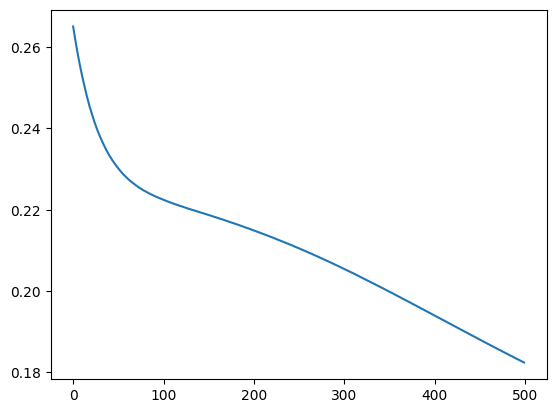

In [7]:
plt.plot(history.history['loss'])
plt.show()

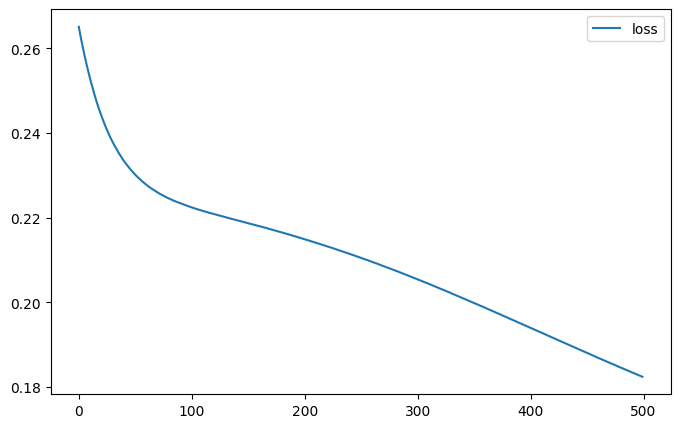

In [8]:
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.show()

In [9]:
model.predict(np.array([[3,3,1,1]]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


array([[0.43774417, 0.3086671 , 0.34004742]], dtype=float32)

## Resultados de la red original

Guardo el loss, la exactitud y el tiempo para poder compararlos con la red de más capas.


In [10]:

loss_original = list(history.history['loss'])
pred_original = model.predict(X, verbose=0)
accuracy_original = np.mean(np.argmax(pred_original, axis=1) == target)
model_original = model

print(f'Loss final original: {loss_original[-1]:.6f}')
print(f'Exactitud original: {accuracy_original:.4f} ({accuracy_original*100:.2f}%)')
print(f'Tiempo original: {original_time:.3f} s')


Loss final original: 0.182420
Exactitud original: 0.6333 (63.33%)
Tiempo original: 27.436 s


# Red con dos capas extra

Aquí se agregan dos Dense(3) antes de la salida. La salida sigue teniendo 3 neuronas porque Iris tiene 3 clases.


In [11]:

deep_model = keras.Sequential(
  [
    layers.Dense(3, activation="sigmoid", name="layer1", input_shape=(4,)),
    layers.Dense(3, activation="sigmoid", name="layer2"),
    layers.Dense(3, activation="sigmoid", name="layer3"),
    layers.Dense(3, activation="sigmoid", name="layer4"),
  ]
)

deep_model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 3)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 3)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer3 (Dense)                  │ (None, 3)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer4 (Dense)                  │ (None, 3)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51 (204.00 B)

 Trainable params: 51 (204.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:

optimizer_deep = tf.keras.optimizers.SGD(learning_rate=0.03)
loss_deep_fn = tf.keras.losses.MeanSquaredError()

deep_model.compile(optimizer=optimizer_deep, loss=loss_deep_fn)

start_time_deep = time.perf_counter()
deep_history = deep_model.fit(X, Y, epochs=500)
deep_time = time.perf_counter() - start_time_deep

print(f'Loss final profundo: {deep_history.history["loss"][-1]:.6f}')
print(f'Tiempo profundo: {deep_time:.3f} s')


Epoch 1/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2469  
Epoch 2/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2463 
Epoch 3/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2457 
Epoch 4/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2451 
Epoch 5/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2445 
Epoch 6/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2440 
Epoch 7/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2434 
Epoch 8/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2429
Epoch 9/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2424 
Epoch 10/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2419 
Epoch 11/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2414 
Epoch 12/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2409 
Epoch 13/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2404 
Epoch 14/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2399 
Epoch 15/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2395 
Epoch 16/500
5/5 ━

Exactitud profunda: 0.3333 (33.33%)


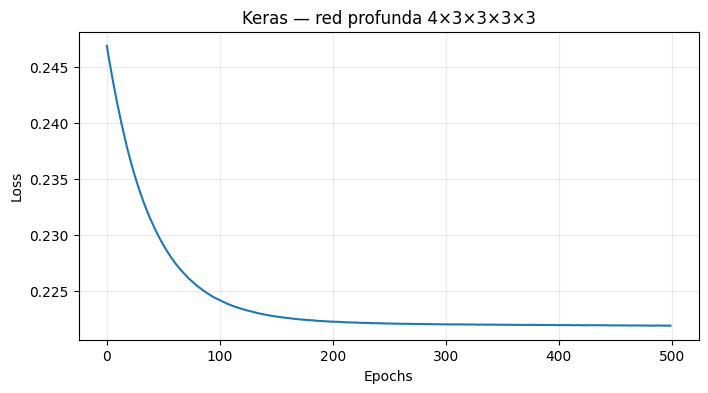

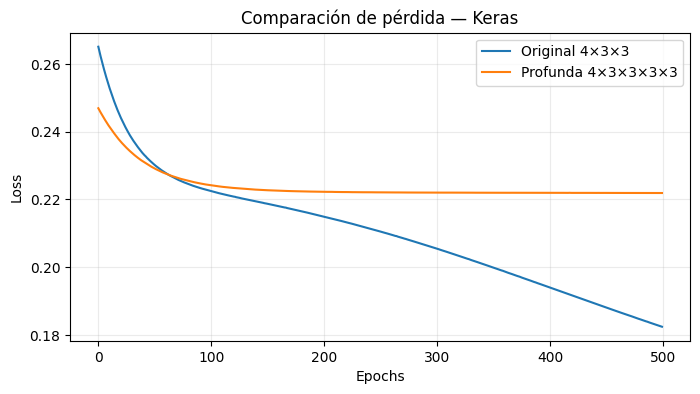


RESUMEN KERAS
Original -> loss=0.182420, exactitud=63.33%, tiempo=27.436s
Profunda -> loss=0.221893, exactitud=33.33%, tiempo=29.188s


In [13]:

pred_deep = deep_model.predict(X, verbose=0)
accuracy_deep = np.mean(np.argmax(pred_deep, axis=1) == target)
loss_deep = list(deep_history.history['loss'])

print(f'Exactitud profunda: {accuracy_deep:.4f} ({accuracy_deep*100:.2f}%)')

plt.figure(figsize=(8, 4))
plt.plot(loss_deep)
plt.xlabel('Epochs'); plt.ylabel('Loss')
plt.title('Keras — red profunda 4×3×3×3×3')
plt.grid(alpha=0.25); plt.show()

plt.figure(figsize=(8, 4))
plt.plot(loss_original, label='Original 4×3×3')
plt.plot(loss_deep, label='Profunda 4×3×3×3×3')
plt.xlabel('Epochs'); plt.ylabel('Loss')
plt.title('Comparación de pérdida — Keras')
plt.legend(); plt.grid(alpha=0.25); plt.show()

print('\nRESUMEN KERAS')
print(f'Original -> loss={loss_original[-1]:.6f}, exactitud={accuracy_original*100:.2f}%, tiempo={original_time:.3f}s')
print(f'Profunda -> loss={loss_deep[-1]:.6f}, exactitud={accuracy_deep*100:.2f}%, tiempo={deep_time:.3f}s')


In [14]:

example = np.array([[3,3,1,1]])
print('Predicción original:', model_original.predict(example, verbose=0))
print('Predicción profunda:', deep_model.predict(example, verbose=0))


Predicción original: [[0.43774417 0.3086671  0.34004742]]
Predicción profunda: [[0.33882794 0.3317596  0.33188224]]


## Evidencias

Para la entrega se pueden tomar capturas de los dos model.summary(), las curvas y el resumen final.
